## 2. `reward_score()` → reward_score ✅ 🧪

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def timescore(time, mid=50, unit=7.5):
    return 1 / (1 + np.exp((np.asarray(time) - mid) / unit))

def taste_part(taste):
    return (np.asarray(taste) / 10) ** 1.5

def effort_part(taste, effort):
    cost = (np.asarray(effort) - 1) / 4
    return 1 - 0.5 * (np.asarray(taste) / 10) * cost

def reward(time, taste, effort):
    return 10 * timescore(time) * taste_part(taste) * effort_part(taste, effort)

def reward_from_ratings(cook_minutes, prep_minutes, taste_ratings, effort_ratings):
    return reward(cook_minutes + prep_minutes, np.mean(taste_ratings), np.mean(effort_ratings))

In [3]:
print(timescore(50), timescore(40))   # 0.5, ≈0.79
print(reward_from_ratings(25, 15, [8, 9, 7], [2, 3]))   # ≈4.81

0.5 0.791391472673955
4.8133259528183565


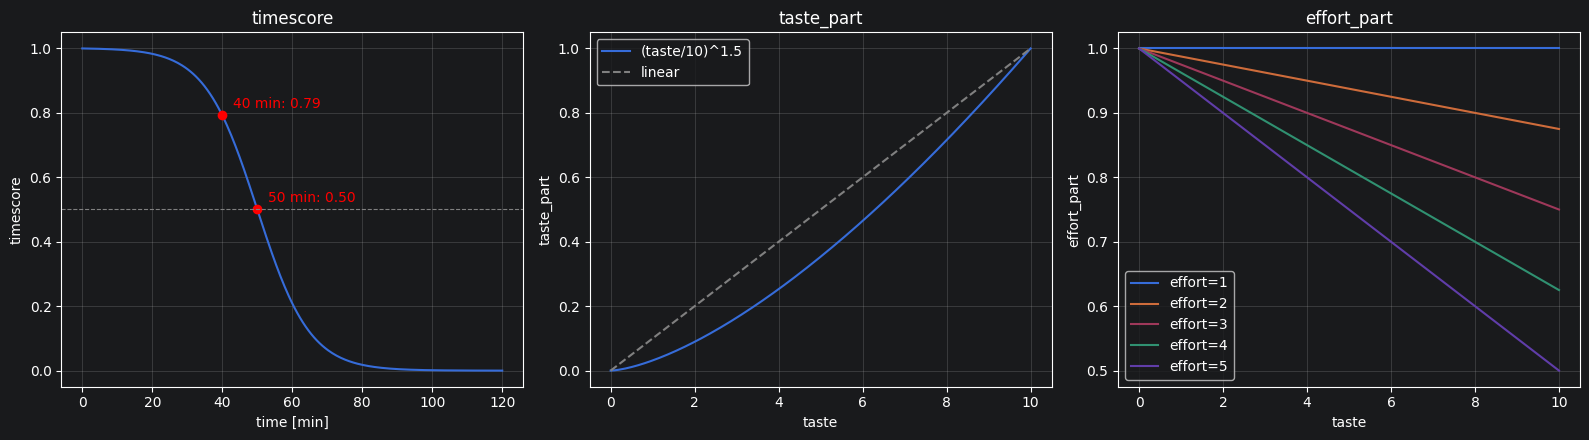

In [4]:
t = np.linspace(0, 120, 300)
ta = np.linspace(0, 10, 200)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ax = axes[0]
ax.plot(t, timescore(t))
for x in [40, 50]:
    ax.plot(x, timescore(x), "ro")
    ax.annotate(f"{x} min: {timescore(x):.2f}", (x, timescore(x)),
                xytext=(8, 5), textcoords="offset points", color="red")
ax.axhline(0.5, color="gray", lw=0.8, ls="--")
ax.set(title="timescore", xlabel="time [min]", ylabel="timescore")

ax = axes[1]
ax.plot(ta, taste_part(ta), label="(taste/10)^1.5")
ax.plot(ta, ta / 10, ls="--", color="gray", label="linear")
ax.set(title="taste_part", xlabel="taste", ylabel="taste_part")
ax.legend()

ax = axes[2]
for e in [1, 2, 3, 4, 5]:
    ax.plot(ta, effort_part(ta, e), label=f"effort={e}")
ax.set(title="effort_part", xlabel="taste", ylabel="effort_part")
ax.legend()

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

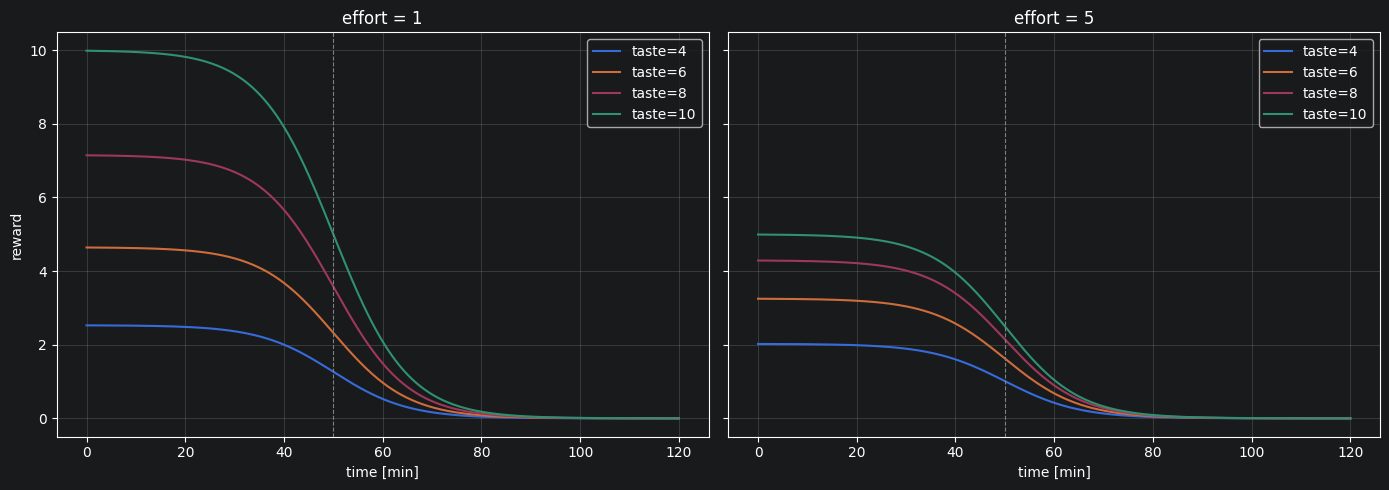

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, e in zip(axes, [1, 5]):
    for tv in [4, 6, 8, 10]:
        ax.plot(t, reward(t, tv, e), label=f"taste={tv}")
    ax.axvline(50, color="gray", lw=0.8, ls="--")
    ax.set(title=f"effort = {e}", xlabel="time [min]")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("reward")
plt.tight_layout()
plt.show()

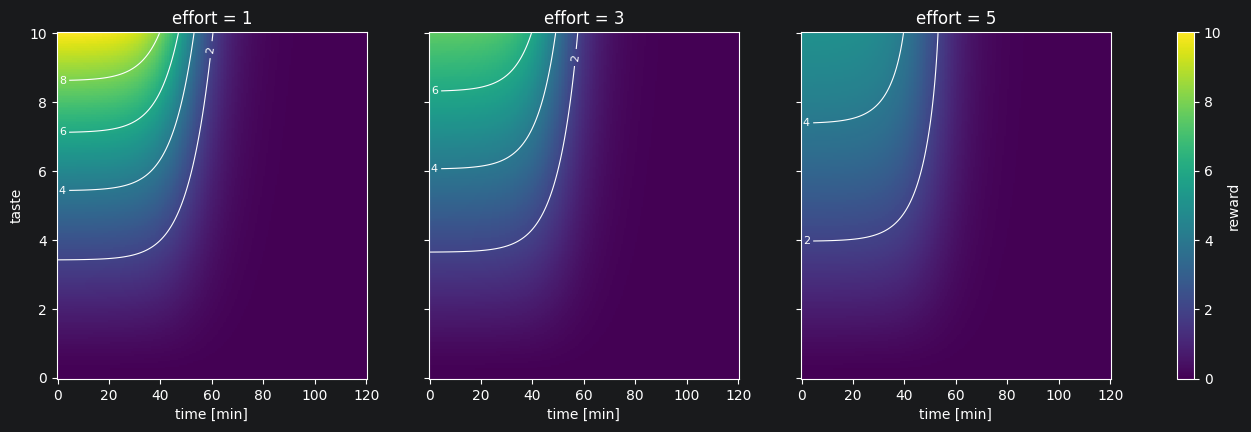

In [6]:
T, TA = np.meshgrid(np.linspace(0, 120, 200), np.linspace(0, 10, 200))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, e in zip(axes, [1, 3, 5]):
    Z = reward(T, TA, e)
    m = ax.pcolormesh(T, TA, Z, shading="auto", cmap="viridis", vmin=0, vmax=10)
    cs = ax.contour(T, TA, Z, levels=[2, 4, 6, 8], colors="white", linewidths=0.8)
    ax.clabel(cs, fontsize=8)
    ax.set(title=f"effort = {e}", xlabel="time [min]")
axes[0].set_ylabel("taste")
fig.colorbar(m, ax=axes, label="reward")
plt.show()

## Sanity Checks

Expected behavior. 🟠 = not tested yet; "old" = value from the old test script, re-check here.

| Situation | Expected | Status |
|---|---|---|
| quick & tasty & low effort | reward ≈ 10 | 🟠 old: 9.82 (20 min, taste 10, effort 1) |
| taste 0 | reward 0 | 🟠 |
| 50 min, otherwise perfect | reward halved | 🟠 |
| bad taste + low effort vs. great taste + high effort | great taste wins | 🟠 old: 0.88 < 4.91 |
| higher taste ⇒ higher reward | monotonically increasing | 🟠 |
| more effort ⇒ lower reward | monotonically decreasing | 🟠 |
| effort effect bad vs. tasty dish | smaller for bad dish | 🟠 old: −10 % vs. −50 % |